In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [6]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [8]:
X = df.drop(columns=['Survived'])
Y = df['Survived']

In [11]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=2)

In [12]:
x_train.head()

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458


In [13]:
x_train['Age_Imputation'] = x_train['Age']
x_test['Age_Imputation'] = x_train['Age']

In [14]:
x_train.head()

,Age,Fare,Age_Imputation
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0


In [24]:
x_train["Age_Imputation"][x_train["Age_Imputation"].isnull()] = x_train["Age"].dropna().sample(x_train["Age"].isnull().sum()).values

C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\1912329023.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  x_train["Age_Imputation"][x_train["Age_Imputation"].isnull()] = x_train["Age"].dropna().sample(x_train["Age"].isnull().sum()).values


In [26]:
x_test["Age_Imputation"][x_test["Age_Imputation"].isnull()] = x_train["Age"].dropna().sample(x_test["Age_Imputation"].isnull().sum(), replace=True).values

C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\2032155241.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  x_test["Age_Imputation"][x_test["Age_Imputation"].isnull()] = x_train["Age"].dropna().sample(x_test["Age_Imputation"].isnull().sum(), replace=True).values


In [28]:
x_train["Age"].isnull().sum()

np.int64(148)

In [29]:
x_train

,Age,Fare,Age_Imputation
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,NaN
493,71.0,49.5042,71.0
527,NaN,221.7792,NaN


C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\3812413543.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train["Age"],hist=False,label="original")
C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\3812413543.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[

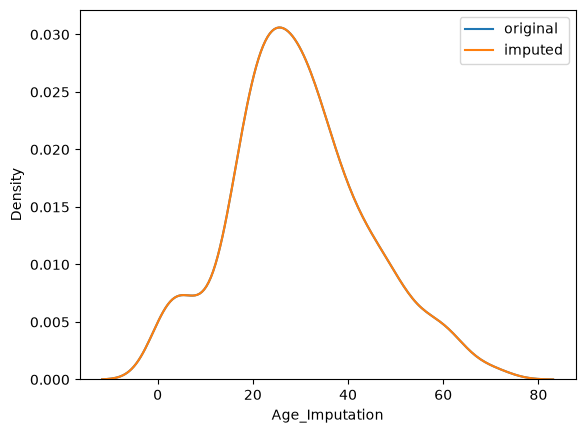

In [36]:
sns.distplot(x_train["Age"],hist=False,label="original")
sns.distplot(x_train["Age_Imputation"],hist=False,label="imputed")

plt.legend()
plt.show()

# In below graph u cant see blue line coz both the lines are overlapping with each other that means both are eaxct same

In [38]:
print("Original Variance of Age:",x_train["Age"].var())
print("Variance Of Imputed Age Column:",x_train["Age_Imputation"].var())

Original Variance of Age: 204.34951339046142
Variance Of Imputed Age Column: 204.34951339046142


In [39]:
x_train[["Age","Fare","Age_Imputation"]].cov()

,Age,Fare,Age_Imputation
Age,204.349513,71.512440,204.349513
Fare,71.512440,2368.246832,71.512440
Age_Imputation,204.349513,71.512440,204.349513


<Axes: >

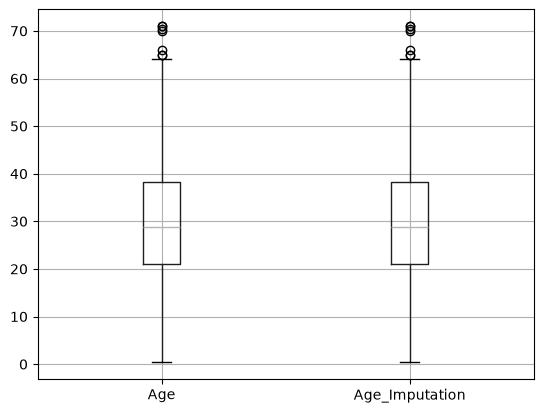

In [40]:
x_train[["Age","Age_Imputation"]].boxplot()

In [42]:
sampled_value = x_train['Age'].dropna().sample(1, random_state=42)

# This code will generate the same output in for the same input

## For Categorical Data

In [43]:
data = pd.read_csv('house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [44]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [45]:
X=data
Y=data['SalePrice']

In [46]:
X_train,X_test,Y_train ,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)


X_train["GarageQual_imputed"]=X_train["GarageQual"]
X_test["GarageQual_imputed"]=X_test["GarageQual"]

X_train["FireplaceQu_imputed"]=X_train["FireplaceQu"]
X_test["FireplaceQu_imputed"]=X_test["FireplaceQu"]

In [47]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
89,NaN,NaN,123600,NaN,NaN
639,Gd,TA,264561,TA,Gd
1357,Fa,TA,149900,TA,Fa
583,Gd,Gd,325000,Gd,Gd
57,NaN,TA,196500,TA,NaN


In [48]:
X_train["GarageQual_imputed"][X_train["GarageQual_imputed"].isnull()]=X_train["GarageQual"].dropna().sample(X_train["GarageQual"].isnull().sum()).values
X_test["GarageQual_imputed"][X_test["GarageQual_imputed"].isnull()]=X_train["GarageQual"].dropna().sample(X_test["GarageQual"].isnull().sum()).values

X_train["FireplaceQu_imputed"][X_train["FireplaceQu_imputed"].isnull()]=X_train["FireplaceQu"].dropna().sample(X_train["FireplaceQu"].isnull().sum()).values
X_test["FireplaceQu_imputed"][X_test["FireplaceQu_imputed"].isnull()]=X_train["FireplaceQu"].dropna().sample(X_test["FireplaceQu"].isnull().sum()).values

C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\2354037950.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  X_train["GarageQual_imputed"][X_train["GarageQual_imputed"].isnull()]=X_train["GarageQual"].dropna().sample(X_train["GarageQual"].isnull().sum()).values
C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\2354037950.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update th

In [49]:
temp=pd.concat([
    X_train["GarageQual"].value_counts()/len(X_train["GarageQual"].dropna()),
    X_train["GarageQual_imputed"].value_counts()/len(X_train)
],axis=1)

temp.columns=["original","imputed"]

In [50]:
temp

,original,imputed
TA,0.951087,0.898973
Fa,0.032609,0.030822
Gd,0.011775,0.011130
Ex,0.002717,0.002568
Po,0.001812,0.001712


In [51]:
temp=pd.concat([
    X_train["FireplaceQu"].value_counts()/len(X_train["FireplaceQu"].dropna()),
    X_train["FireplaceQu_imputed"].value_counts()/len(X_train)
],axis=1)

temp.columns=["original","imputed"]

In [52]:
temp

,original,imputed
Gd,0.491143,0.261130
TA,0.405797,0.215753
Fa,0.043478,0.023116
Ex,0.033816,0.017979
Po,0.025765,0.013699


C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\2871616391.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train["FireplaceQu"]==category]["SalePrice"],hist=False,label=category)
C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\2871616391.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6

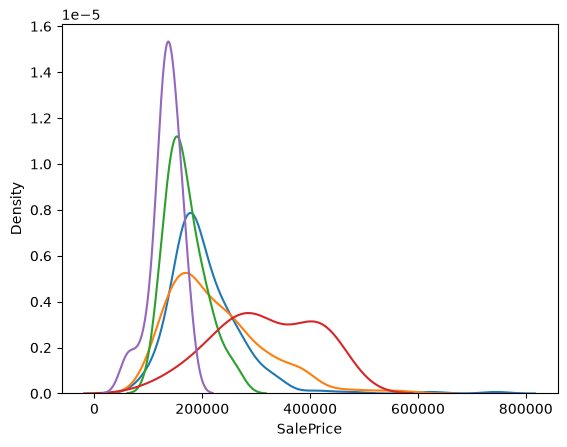

In [54]:
for category in X_train["FireplaceQu"].dropna().unique():
    sns.distplot(X_train[X_train["FireplaceQu"]==category]["SalePrice"],hist=False,label=category)

plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\639216775.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train["GarageQual"]==category]["SalePrice"],hist=False,label=category)
C:\Users\Admin\AppData\Local\Temp\ipykernel_18504\639216775.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372

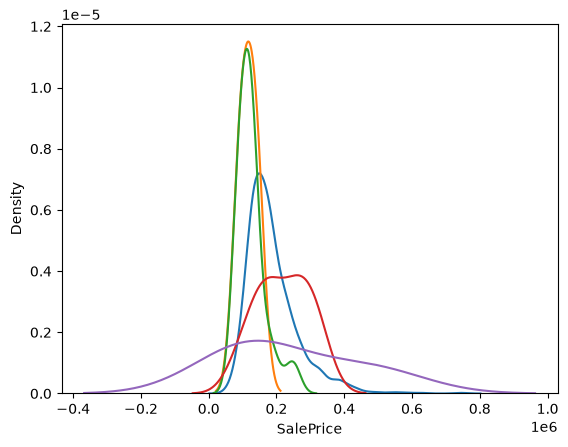

In [56]:
for category in X_train["GarageQual"].dropna().unique():
    sns.distplot(X_train[X_train["GarageQual"]==category]["SalePrice"],hist=False,label=category)
plt.show()

In [57]:
# We can see that Random Sample Impuation for categorical Columns , it is causing changes in distribution of data